<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/notebooks/ContentRefreshRecommendationEngine/FlyRank_Content_Refresh_Recommendation_Engine_Stage1_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FlyRank — Content Refresh Recommendation Engine (DuckDB)

## Stage 1: baseline validation

This notebook builds a transparent content-refresh recommendation queue and adds explicit checks for data quality, joins, missing values, score consistency, and recommendations across clients.

## Output
- Priority score and tier (HIGH / MEDIUM / LOW)
- Explanation and suggested action for each content item
- Data-quality diagnostics and multi-client review tables
- CSV exports for editorial review

**Important:** scores are heuristic ranking aids, not probabilities or causal estimates of refresh impact. The notebook has not been pre-run against your authenticated warehouse; run it top-to-bottom in Colab and inspect the diagnostics before relying on the queue.


In [1]:
%pip -q install duckdb huggingface_hub pandas numpy matplotlib seaborn

## 1. Authenticate to Hugging Face

In Colab, add `HF_TOKEN` under Secrets and enable notebook access.

In [2]:
import os
from getpass import getpass

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    HF_TOKEN = getpass("Hugging Face token (input hidden): ")
if not HF_TOKEN:
    raise ValueError("HF_TOKEN is required.")

Hugging Face token (input hidden): ··········


In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect()
safe_token = HF_TOKEN.replace("'", "''")
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{safe_token}')")

REL = "hf://datasets/FlyRank/internship-warehouse"
TABLES = {
    "dim_clients": f"read_parquet('{REL}/dim_clients.parquet')",
    "dim_content": f"read_parquet('{REL}/dim_content.parquet')",
    "fact_daily": f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    "fact_daily_sample": f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    "fact_query_90d": f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}
print("DuckDB connection ready.")

DuckDB connection ready.


## 2. Inspect available content metadata

We inspect the dimension schema rather than assuming publication date, last-updated date, title, or URL columns exist. These fields will be used only if found and suitable.

In [4]:
content_schema = con.execute(f"DESCRIBE SELECT * FROM {TABLES['dim_content']}").df()
display(content_schema)
content_columns = content_schema["column_name"].tolist()
print("Available content dimension columns:")
print(content_columns)

,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,content_hash_id,VARCHAR,YES,None,None,None
2,keyword_hash_id,VARCHAR,YES,None,None,None
3,url_hash_id,VARCHAR,YES,None,None,None
4,keyword_char_count,BIGINT,YES,None,None,None
5,keyword_token_count,BIGINT,YES,None,None,None
6,url_char_count,BIGINT,YES,None,None,None
7,content_created_date,DATE,YES,None,None,None
8,content_updated_date,DATE,YES,None,None,None
9,content_type,VARCHAR,YES,None,None,None


Available content dimension columns:
['client_hash_id', 'content_hash_id', 'keyword_hash_id', 'url_hash_id', 'keyword_char_count', 'keyword_token_count', 'url_char_count', 'content_created_date', 'content_updated_date', 'content_type', 'search_volume', 'competition', 'competition_level', 'cpc', 'main_intent', 'backlinks', 'category_count', 'keyword_created_date', 'provider_used', 'model_used', 'char_count', 'word_count', 'last_optimized_date', 'optimization_eligible_date', 'is_published', 'is_deleted']


## 3. Aggregate performance and search-demand signals in DuckDB

Features include recent vs previous 30-day impressions/clicks, CTR, average position, ranking volatility, and 90-day query-mix signals. The SQL pushes the large-table aggregation into DuckDB before materializing the smaller result in Python.

In [5]:
recommendation_sql = f'''
WITH bounds AS (
    SELECT MAX(report_date) AS end_d FROM {TABLES["fact_daily"]}
),
daily AS (
    SELECT
        f.client_hash_id,
        f.content_hash_id,
        SUM(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                 THEN COALESCE(f.gsc_impressions, 0) ELSE 0 END) AS imp_last30,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                  AND f.report_date > b.end_d - INTERVAL 60 DAY
                 THEN COALESCE(f.gsc_impressions, 0) ELSE 0 END) AS imp_prev30,
        SUM(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                 THEN COALESCE(f.gsc_clicks, 0) ELSE 0 END) AS clk_last30,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                  AND f.report_date > b.end_d - INTERVAL 60 DAY
                 THEN COALESCE(f.gsc_clicks, 0) ELSE 0 END) AS clk_prev30,
        AVG(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                 THEN f.gsc_avg_position END) AS pos_last30,
        AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                  AND f.report_date > b.end_d - INTERVAL 60 DAY
                 THEN f.gsc_avg_position END) AS pos_prev30,
        STDDEV_SAMP(f.gsc_avg_position) AS pos_volatility_60d,
        MAX(b.end_d) AS data_end_date
    FROM {TABLES["fact_daily"]} f
    CROSS JOIN bounds b
    WHERE f.report_date > b.end_d - INTERVAL 60 DAY
    GROUP BY f.client_hash_id, f.content_hash_id
    HAVING SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                     AND f.report_date > b.end_d - INTERVAL 60 DAY
                    THEN COALESCE(f.gsc_impressions, 0) ELSE 0 END) >= 20
),
qsignals AS (
    SELECT
        content_hash_id,
        ANY_VALUE(content_visible_query_count) AS visible_queries,
        ANY_VALUE(rare_impressions_share) AS rare_share,
        ANY_VALUE(anonymized_impressions_share) AS anon_share,
        MAX(impressions_90d) AS top_query_impressions,
        SUM(impressions_90d) AS kept_query_impressions
    FROM {TABLES["fact_query_90d"]}
    GROUP BY content_hash_id
)
SELECT d.*,
       (d.imp_last30 - d.imp_prev30) / NULLIF(d.imp_prev30, 0) AS trend_pct,
       d.clk_last30 / NULLIF(d.imp_last30, 0) AS ctr_last30,
       d.clk_prev30 / NULLIF(d.imp_prev30, 0) AS ctr_prev30,
       d.pos_last30 - d.pos_prev30 AS position_change,
       q.visible_queries,
       q.rare_share,
       q.anon_share,
       q.top_query_impressions,
       q.kept_query_impressions,
       q.top_query_impressions / NULLIF(q.kept_query_impressions, 0) AS top_query_share
FROM daily d
LEFT JOIN qsignals q ON d.content_hash_id = q.content_hash_id
'''
performance = con.execute(recommendation_sql).df()
print(f"Client-content rows: {len(performance):,}")
display(performance.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Client-content rows: 157,464


,client_hash_id,content_hash_id,imp_last30,imp_prev30,clk_last30,clk_prev30,pos_last30,pos_prev30,pos_volatility_60d,data_end_date,trend_pct,ctr_last30,ctr_prev30,position_change,visible_queries,rare_share,anon_share,top_query_impressions,kept_query_impressions,top_query_share
0,client_08a6a72ff48e62c0,content_5f6556f5a53e47f0,0.0,60.0,0.0,0.0,NaN,73.298611,24.154344,2026-06-30,-1.000000,NaN,0.000000,NaN,1,0.564103,0.141026,23,23.0,1.000000
1,client_08a6a72ff48e62c0,content_5f6fae04728d32ab,155.0,49.0,0.0,0.0,77.434557,46.069444,30.043735,2026-06-30,2.163265,0.000000,0.000000,31.365113,5,0.191038,0.471698,54,143.0,0.377622
2,client_08a6a72ff48e62c0,content_5f71205e0b46f70a,2479.0,3341.0,5.0,14.0,6.314476,4.622416,1.194352,2026-06-30,-0.258007,0.002017,0.004190,1.692060,12,0.036253,0.910266,137,447.0,0.306488
3,client_08a6a72ff48e62c0,content_5f716493f7989b45,200.0,584.0,0.0,2.0,17.358072,10.117632,7.080594,2026-06-30,-0.657534,0.000000,0.003425,7.240441,17,0.095416,0.650608,116,543.0,0.213628
4,client_08a6a72ff48e62c0,content_5f8b67a6b0494e15,12.0,72.0,0.0,0.0,7.729167,43.346907,31.771619,2026-06-30,-0.833333,0.000000,0.000000,-35.617740,1,0.217857,0.689286,26,26.0,1.000000


## 4. Attach optional content metadata

This step looks for a content identifier plus likely URL/title and date fields. If the schema has multiple candidates, it uses the first matching candidate and prints the selection. If no reliable update/publication date is found, age will be unavailable and will not influence the score.

In [6]:
# Candidate names are matched case-insensitively; actual column names come from the inspected schema.
lower_to_actual = {c.lower(): c for c in content_columns}

def first_existing(candidates):
    for name in candidates:
        if name.lower() in lower_to_actual:
            return lower_to_actual[name.lower()]
    return None

content_key = first_existing(["content_hash_id"])
title_col = first_existing(["title", "content_title", "page_title", "meta_title"])
url_col = first_existing(["url", "canonical_url", "page_url", "content_url"])
date_col = first_existing(["last_updated_at", "updated_at", "last_modified", "modified_at",
                           "published_at", "publication_date", "created_at", "published_date"])

print("Join key:", content_key)
print("Title field:", title_col)
print("URL field:", url_col)
print("Potential age/date field:", date_col)

if content_key is None:
    print("No content_hash_id in dim_content; recommendations will use performance data only.")
    recs = performance.copy()
else:
    selected = [content_key]
    if title_col: selected.append(title_col)
    if url_col and url_col not in selected: selected.append(url_col)
    if date_col and date_col not in selected: selected.append(date_col)
    projection = ", ".join([f'"{c}"' for c in selected])
    meta = con.execute(f"SELECT {projection} FROM {TABLES['dim_content']}").df()
    rename = {content_key: "content_hash_id"}
    if title_col: rename[title_col] = "content_title"
    if url_col: rename[url_col] = "content_url"
    if date_col: rename[date_col] = "content_date_metadata"
    meta = meta.rename(columns=rename)
    metadata_duplicate_rows = int(meta.duplicated(subset=["content_hash_id"], keep=False).sum())
    metadata_duplicate_keys = int(meta.loc[meta.duplicated(subset=["content_hash_id"], keep=False), "content_hash_id"].nunique())
    # The dimension should ideally have one row per content key. Deduplicate for a safe join,
    # while exposing the duplicate counts so they can be investigated rather than hidden.
    meta = meta.drop_duplicates(subset=["content_hash_id"])
    recs = performance.merge(meta, on="content_hash_id", how="left", indicator="_metadata_merge")
    recs["metadata_matched"] = recs["_metadata_merge"].eq("both")
    recs = recs.drop(columns=["_metadata_merge"])

if content_key is None:
    metadata_duplicate_rows = 0
    metadata_duplicate_keys = 0
    recs["metadata_matched"] = False
if "content_title" not in recs.columns: recs["content_title"] = pd.NA
if "content_url" not in recs.columns: recs["content_url"] = pd.NA
if "content_date_metadata" not in recs.columns: recs["content_date_metadata"] = pd.NaT

recs["content_date_metadata"] = pd.to_datetime(recs["content_date_metadata"], errors="coerce", utc=True)
recs["data_end_date"] = pd.to_datetime(recs["data_end_date"], errors="coerce", utc=True)
recs["content_age_days"] = (recs["data_end_date"] - recs["content_date_metadata"]).dt.days
# Use age only for plausible non-negative ages. Future or malformed dates are ignored.
recs.loc[(recs["content_age_days"] < 0) | (recs["content_age_days"] > 10000), "content_age_days"] = np.nan
print("Rows after metadata join:", f"{len(recs):,}")
print("Rows with usable content age:", f"{recs['content_age_days'].notna().sum():,}")
display(recs[["client_hash_id","content_hash_id","content_title","content_url","content_age_days"]].head())

Join key: content_hash_id
Title field: None
URL field: None
Potential age/date field: None
Rows after metadata join: 157,464
Rows with usable content age: 0


,client_hash_id,content_hash_id,content_title,content_url,content_age_days
0,client_08a6a72ff48e62c0,content_5f6556f5a53e47f0,<NA>,<NA>,NaN
1,client_08a6a72ff48e62c0,content_5f6fae04728d32ab,<NA>,<NA>,NaN
2,client_08a6a72ff48e62c0,content_5f71205e0b46f70a,<NA>,<NA>,NaN
3,client_08a6a72ff48e62c0,content_5f716493f7989b45,<NA>,<NA>,NaN
4,client_08a6a72ff48e62c0,content_5f8b67a6b0494e15,<NA>,<NA>,NaN


## 4.1 Validate joins and key uniqueness

These checks reveal duplicate keys and join coverage. A low metadata match rate may be acceptable if the dimension is incomplete, but it should be understood before interpreting titles, URLs, or content age.

In [7]:
# Performance aggregation should contain one row per client-content pair.
perf_duplicate_pairs = int(performance.duplicated(["client_hash_id", "content_hash_id"]).sum())

# Check content dimension key uniqueness before the notebook's safe deduplication.
content_schema_check = con.execute(f"DESCRIBE SELECT * FROM {TABLES['dim_content']}").df()
content_key_in_schema = "content_hash_id" in content_schema_check["column_name"].tolist()

join_audit = pd.DataFrame([
    {"check": "Performance duplicate client-content rows", "value": perf_duplicate_pairs, "interpretation": "Expected 0 after SQL aggregation"},
    {"check": "Dimension duplicate rows on content key", "value": metadata_duplicate_rows, "interpretation": "Investigate if > 0; deduplication is only a safety measure"},
    {"check": "Dimension duplicate content keys", "value": metadata_duplicate_keys, "interpretation": "Ideally 0 duplicate keys"},
    {"check": "Performance rows with metadata match", "value": int(recs["metadata_matched"].sum()), "interpretation": "Compare with total rows below"},
    {"check": "Performance rows without metadata match", "value": int((~recs["metadata_matched"]).sum()), "interpretation": "Could indicate missing/inconsistent content keys"},
])
display(join_audit)
print(f"Metadata match rate: {recs['metadata_matched'].mean():.1%} across {len(recs):,} recommendation rows")

# Inspect the client dimension without assuming its optional display-name column.
client_schema = con.execute(f"DESCRIBE SELECT * FROM {TABLES['dim_clients']}").df()
client_columns = client_schema["column_name"].tolist()
print("dim_clients columns:", client_columns)
client_key = next((c for c in client_columns if c.lower() in ["client_hash_id", "client_id"]), None)
client_label = next((c for c in client_columns if c.lower() in ["client_name", "name", "client", "domain", "website", "site_name"]), None)
if client_key is not None:
    clients = con.execute(f'SELECT "{client_key}" AS client_hash_id' + (f', "{client_label}" AS client_label' if client_label else '') + f' FROM {TABLES["dim_clients"]}').df()
    client_dup_keys = int(clients.duplicated("client_hash_id", keep=False).sum())
    print(f"Client dimension duplicate-key rows: {client_dup_keys:,}")
    if client_dup_keys == 0:
        if client_label:
            recs = recs.merge(clients, on="client_hash_id", how="left")
        else:
            recs["client_label"] = recs["client_hash_id"].astype(str)
    else:
        print("Client labels not joined because client_hash_id is not unique; use IDs for this run.")
        recs["client_label"] = recs["client_hash_id"].astype(str)
else:
    print("No recognized client key found; using client_hash_id only.")
    recs["client_label"] = recs["client_hash_id"].astype(str)

print("Rows after optional client label join:", f"{len(recs):,}")


,check,value,interpretation
0,Performance duplicate client-content rows,0,Expected 0 after SQL aggregation
1,Dimension duplicate rows on content key,0,Investigate if > 0; deduplication is only a sa...
2,Dimension duplicate content keys,0,Ideally 0 duplicate keys
3,Performance rows with metadata match,157464,Compare with total rows below
4,Performance rows without metadata match,0,Could indicate missing/inconsistent content keys


Metadata match rate: 100.0% across 157,464 recommendation rows
dim_clients columns: ['client_hash_id', 'is_active', 'has_gsc_access', 'has_ga4_access', 'access_profile', 'client_created_date', 'client_updated_date', 'gsc_data_start', 'ga4_data_start']
Client dimension duplicate-key rows: 0
Rows after optional client label join: 157,464


## 5. Build transparent recommendation signals

We score each article on four dimensions:
1. **Decline severity** — negative recent impression trend.
2. **Search demand / opportunity** — recent and prior impressions plus visible query count.
3. **Page-one opportunity** — average position between 4 and 20, where a content improvement may be worth investigating.
4. **Content age** — only if a usable date column exists in the content dimension.

The weights are an initial business hypothesis. The score is a prioritization heuristic, not a calibrated probability of traffic recovery.

In [8]:
# 1) Decline severity: map trend_pct into 0..1
trend = recs["trend_pct"].replace([np.inf, -np.inf], np.nan)
recs["decline_signal"] = ((-trend - 0.05) / 0.75).clip(0, 1).fillna(0)

# 2) Demand signal: relative within the current dataset, using log scale to reduce skew
log_impressions = np.log1p(recs[["imp_last30", "imp_prev30"]].clip(lower=0).max(axis=1))
def percentile_rank(s):
    s = pd.to_numeric(s, errors="coerce")
    return s.rank(pct=True).fillna(0)
recs["demand_signal"] = percentile_rank(log_impressions)

visible_queries = pd.to_numeric(recs["visible_queries"], errors="coerce")
recs["query_coverage_signal"] = percentile_rank(np.log1p(visible_queries.clip(lower=0)))

# 3) Ranking opportunity: strongest for positions roughly 4-20, weaker outside
pos = pd.to_numeric(recs["pos_last30"], errors="coerce")
recs["page_one_opportunity_signal"] = np.select(
    [(pos >= 4) & (pos <= 10), (pos > 10) & (pos <= 20), (pos > 20) & (pos <= 30), (pos > 0) & (pos < 4)],
    [1.0, 0.8, 0.45, 0.35],
    default=0.0
)
recs.loc[pos.isna(), "page_one_opportunity_signal"] = 0.0

# 4) Age signal: 1 when >= 730 days, 0 at <= 90 days; linear between.
age = pd.to_numeric(recs["content_age_days"], errors="coerce")
recs["age_signal"] = ((age - 90) / (730 - 90)).clip(0, 1)
recs["age_signal_available"] = age.notna()

# If no age metadata is available, remove age from the weighted score and renormalize.
base_weights = {
    "decline_signal": 0.40,
    "demand_signal": 0.25,
    "page_one_opportunity_signal": 0.25,
    "age_signal": 0.10
}
weighted_sum = (
    base_weights["decline_signal"] * recs["decline_signal"] +
    base_weights["demand_signal"] * recs["demand_signal"] +
    base_weights["page_one_opportunity_signal"] * recs["page_one_opportunity_signal"] +
    base_weights["age_signal"] * recs["age_signal"].fillna(0)
)
available_weight = (
    base_weights["decline_signal"] + base_weights["demand_signal"] +
    base_weights["page_one_opportunity_signal"] +
    base_weights["age_signal"] * recs["age_signal_available"].astype(float)
)
recs["priority_score"] = (100 * weighted_sum / available_weight).round(1)

recs["priority_tier"] = np.select(
    [recs["priority_score"] >= 70, recs["priority_score"] >= 45],
    ["HIGH", "MEDIUM"], default="LOW"
)
display(recs["priority_tier"].value_counts().to_frame("articles"))

,articles
priority_tier,
MEDIUM,70718
LOW,55114
HIGH,31632


## 5.1 Missing-value and feature-quality audit

Missing values are not automatically errors: query signals and content dates may be unavailable. However, missing performance fields, ratios, or join keys can affect ranking quality.

In [9]:
audit_columns = [c for c in [
    "client_hash_id", "content_hash_id", "imp_last30", "imp_prev30", "clk_last30", "clk_prev30",
    "pos_last30", "pos_prev30", "trend_pct", "ctr_last30", "ctr_prev30", "visible_queries",
    "content_title", "content_url", "content_age_days", "priority_score", "priority_tier"
] if c in recs.columns]
missing_audit = pd.DataFrame({
    "column": audit_columns,
    "missing_count": [int(recs[c].isna().sum()) for c in audit_columns],
    "missing_pct": [round(float(recs[c].isna().mean() * 100), 2) for c in audit_columns],
    "dtype": [str(recs[c].dtype) for c in audit_columns],
}).sort_values("missing_pct", ascending=False)
display(missing_audit)

# Basic checks on expected numerical fields.
for col in ["imp_last30", "imp_prev30", "clk_last30", "clk_prev30"]:
    if col in recs.columns:
        negative_count = int((pd.to_numeric(recs[col], errors="coerce") < 0).sum())
        print(f"Negative values in {col}: {negative_count:,}")


,column,missing_count,missing_pct,dtype
13,content_url,157464,100.00,object
12,content_title,157464,100.00,object
14,content_age_days,157464,100.00,float64
11,visible_queries,33917,21.54,Int64
6,pos_last30,6335,4.02,float64
9,ctr_last30,6335,4.02,float64
0,client_hash_id,0,0.00,object
3,imp_prev30,0,0.00,float64
1,content_hash_id,0,0.00,object
8,trend_pct,0,0.00,float64


Negative values in imp_last30: 0
Negative values in imp_prev30: 0
Negative values in clk_last30: 0
Negative values in clk_prev30: 0


## 5.2 Validate score range and tier consistency

These are mechanical assertions about the scoring implementation, not proof that the weights are business-optimal.

In [10]:
score = pd.to_numeric(recs["priority_score"], errors="coerce")
score_checks = {
    "all_scores_present": bool(score.notna().all()),
    "minimum_score": float(score.min()) if score.notna().any() else np.nan,
    "maximum_score": float(score.max()) if score.notna().any() else np.nan,
    "scores_within_0_100": bool(score.dropna().between(0, 100).all()),
    "high_tier_threshold_consistent": bool((recs.loc[score >= 70, "priority_tier"].astype(str) == "HIGH").all()),
    "medium_tier_threshold_consistent": bool((recs.loc[(score >= 45) & (score < 70), "priority_tier"].astype(str) == "MEDIUM").all()),
    "low_tier_threshold_consistent": bool((recs.loc[score < 45, "priority_tier"].astype(str) == "LOW").all()),
    "rows": int(len(recs)),
}
display(pd.DataFrame([score_checks]).T.rename(columns={0: "result"}))
if not score_checks["scores_within_0_100"] or not all(score_checks[k] for k in ["all_scores_present", "high_tier_threshold_consistent", "medium_tier_threshold_consistent", "low_tier_threshold_consistent"]):
    print("WARNING: at least one score validation failed; inspect the scoring cells before using the queue.")
else:
    print("Score range and tier threshold checks passed.")

# The score's components should all be bounded 0..1.
component_cols = [c for c in ["decline_signal", "demand_signal", "page_one_opportunity_signal", "age_signal"] if c in recs.columns]
component_audit = pd.DataFrame([
    {"component": c, "min": pd.to_numeric(recs[c], errors="coerce").min(), "max": pd.to_numeric(recs[c], errors="coerce").max(), "missing_pct": recs[c].isna().mean() * 100}
    for c in component_cols
])
display(component_audit)


,result
all_scores_present,True
minimum_score,0.1
maximum_score,100.0
scores_within_0_100,True
high_tier_threshold_consistent,True
medium_tier_threshold_consistent,True
low_tier_threshold_consistent,True
rows,157464


Score range and tier threshold checks passed.


,component,min,max,missing_pct
0,decline_signal,0.000000,1.0,0.0
1,demand_signal,0.003115,1.0,0.0
2,page_one_opportunity_signal,0.000000,1.0,0.0
3,age_signal,NaN,NaN,100.0


## 6. Generate reasons and recommended actions

Reasons are assembled from observed signals. They explain why an article received its score, rather than merely returning a priority label.

In [11]:
high_impression_threshold = recs[["imp_last30", "imp_prev30"]].max(axis=1).quantile(0.75)
high_query_threshold = pd.to_numeric(recs["visible_queries"], errors="coerce").quantile(0.75)

def build_reasons(row):
    reasons = []
    t = row.get("trend_pct")
    if pd.notna(t):
        if t <= -0.50: reasons.append(f"Impressions fell {abs(t):.0%} vs previous 30 days")
        elif t <= -0.20: reasons.append(f"Impressions declined {abs(t):.0%} vs previous 30 days")
        elif t < -0.05: reasons.append("Impressions show a mild decline")
    if pd.notna(row.get("imp_last30")) and pd.notna(row.get("imp_prev30")):
        if max(row["imp_last30"], row["imp_prev30"]) >= high_impression_threshold:
            reasons.append("Relatively high impression volume in this dataset")
    p = row.get("pos_last30")
    if pd.notna(p):
        if 4 <= p <= 10: reasons.append(f"Ranking near page-one boundary (average position {p:.1f})")
        elif 10 < p <= 20: reasons.append(f"Page-two opportunity (average position {p:.1f})")
    q = row.get("visible_queries")
    if pd.notna(q) and q >= high_query_threshold:
        reasons.append("Broad visible query coverage")
    age_days = row.get("content_age_days")
    if pd.notna(age_days) and age_days >= 730:
        reasons.append(f"Content metadata date is about {age_days/365:.1f} years old")
    if not reasons:
        reasons.append("No single strong signal; review trend, rankings, and query coverage")
    return reasons

def suggest_action(row):
    actions = []
    t, p = row.get("trend_pct"), row.get("pos_last30")
    if pd.notna(t) and t <= -0.20:
        actions.append("Audit search intent, SERP changes, internal links, and content freshness")
    if pd.notna(p) and 4 <= p <= 20:
        actions.append("Improve title/meta description, answer coverage, and on-page relevance")
    if pd.notna(row.get("content_age_days")) and row["content_age_days"] >= 730:
        actions.append("Verify facts, dates, examples, and outdated references")
    if pd.notna(row.get("ctr_last30")) and pd.notna(row.get("pos_last30")):
        if row["pos_last30"] <= 10 and row["ctr_last30"] < row.get("ctr_prev30", np.nan):
            actions.append("Investigate CTR decline; test title/snippet improvements")
    if not actions:
        actions.append("Review the evidence manually before scheduling a refresh")
    return actions

recs["reasons"] = recs.apply(build_reasons, axis=1)
recs["recommended_actions"] = recs.apply(suggest_action, axis=1)
recs["reasons_text"] = recs["reasons"].apply(lambda xs: " | ".join(xs))
recs["actions_text"] = recs["recommended_actions"].apply(lambda xs: " | ".join(xs))
recs["refresh_recommendation"] = np.select(
    [recs["priority_tier"].eq("HIGH"), recs["priority_tier"].eq("MEDIUM")],
    ["Review for refresh soon", "Add to refresh review backlog"],
    default="Monitor; refresh only if other evidence supports it"
)


## 7. Inspect the highest-priority recommendations

The table shows the score, tier, reasons, suggested actions, and evidence metrics. Treat the priority score as a ranking aid, not a probability.

In [12]:
recs["priority_rank"] = recs.groupby("client_hash_id")["priority_score"].rank(method="first", ascending=False).astype(int)
columns_to_show = [
    "client_hash_id","content_hash_id","content_title","content_url",
    "priority_rank","priority_score","priority_tier","refresh_recommendation",
    "reasons_text","actions_text","trend_pct","imp_last30","imp_prev30",
    "clk_last30","clk_prev30","ctr_last30","ctr_prev30","pos_last30",
    "position_change","visible_queries","content_age_days"
]
columns_to_show = [c for c in columns_to_show if c in recs.columns]
tier_order = pd.CategoricalDtype(["HIGH", "MEDIUM", "LOW"], ordered=True)
recs["priority_tier"] = recs["priority_tier"].astype(tier_order)
display(recs.sort_values(["priority_tier","priority_score"],ascending=[True,False])[columns_to_show].head(100))

,client_hash_id,content_hash_id,content_title,content_url,priority_rank,priority_score,priority_tier,refresh_recommendation,reasons_text,actions_text,...,imp_last30,imp_prev30,clk_last30,clk_prev30,ctr_last30,ctr_prev30,pos_last30,position_change,visible_queries,content_age_days
19832,client_3f0ce4d44fe94f3d,content_f79972e4438a9a03,<NA>,<NA>,1,100.0,HIGH,Review for refresh soon,Impressions fell 92% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,5790.0,70775.0,11.0,26.0,0.001900,0.000367,8.802433,-0.418489,236,NaN
25676,client_157ffe4d4a595515,content_9648c4d1595a0794,<NA>,<NA>,1,100.0,HIGH,Review for refresh soon,Impressions fell 97% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,6001.0,213610.0,12.0,52.0,0.002000,0.000243,4.520348,1.977273,464,NaN
42639,client_73cda7b4e4f265ea,content_9610ee5585b7a7fc,<NA>,<NA>,1,100.0,HIGH,Review for refresh soon,Impressions fell 85% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,12572.0,83715.0,4.0,8.0,0.000318,0.000096,9.646745,-0.000899,53,NaN
99646,client_73cda7b4e4f265ea,content_425715547c6a3ea8,<NA>,<NA>,2,100.0,HIGH,Review for refresh soon,Impressions fell 87% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,8020.0,63808.0,0.0,3.0,0.000000,0.000047,9.789446,1.259804,11,NaN
42871,client_73cda7b4e4f265ea,content_b5f3280f8d894862,<NA>,<NA>,3,99.9,HIGH,Review for refresh soon,Impressions fell 85% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,8032.0,53336.0,32.0,88.0,0.003984,0.001650,7.637554,2.597904,133,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122428,client_e547b89c05043229,content_fe2280adc1ddc4d3,<NA>,<NA>,10,98.8,HIGH,Review for refresh soon,Impressions fell 84% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,1409.0,8686.0,1.0,2.0,0.000710,0.000230,9.443963,0.664866,154,NaN
678,client_08a6a72ff48e62c0,content_e7b5dd4dff461ad2,<NA>,<NA>,5,98.7,HIGH,Review for refresh soon,Impressions fell 78% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,48447.0,218715.0,146.0,1921.0,0.003014,0.008783,9.494924,3.625961,607,NaN
10696,client_20259bd6705d81d4,content_37d604ce47631462,<NA>,<NA>,3,98.7,HIGH,Review for refresh soon,Impressions fell 89% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,910.0,8329.0,21.0,44.0,0.023077,0.005283,8.926344,-0.732984,12,NaN
36311,client_73cda7b4e4f265ea,content_5494017dcccc0670,<NA>,<NA>,37,98.7,HIGH,Review for refresh soon,Impressions fell 84% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li...",...,1392.0,8494.0,2.0,8.0,0.001437,0.000942,9.278862,2.681066,90,NaN


## 8.1 Review recommendations across multiple clients

Do not validate the engine from one client's queue alone. This section samples clients with the most eligible content rows and shows each client's top five recommendations. Inspect whether the reasons and actions fit the observed metrics.

In [13]:
client_counts = recs.groupby(["client_hash_id", "client_label"], dropna=False).size().reset_index(name="eligible_content_rows")
client_counts = client_counts.sort_values("eligible_content_rows", ascending=False)
display(client_counts.head(20))

# Choose up to five clients with the most eligible content; can be replaced with specific IDs after inspecting client_counts.
clients_to_review = client_counts.head(5)["client_hash_id"].tolist()
review_cols = [c for c in [
    "client_hash_id", "client_label", "content_hash_id", "content_title", "content_url",
    "priority_rank", "priority_score", "priority_tier", "trend_pct", "imp_last30", "imp_prev30",
    "pos_last30", "visible_queries", "reasons_text", "actions_text"
] if c in recs.columns]
review = (recs[recs["client_hash_id"].isin(clients_to_review)]
          .sort_values(["client_hash_id", "priority_score"], ascending=[True, False])
          .groupby("client_hash_id", group_keys=False).head(5))
display(review[review_cols])

print("Validation questions to answer manually:")
print("1. Does each high-priority row have a plausible decline, demand, ranking, or age signal? ")
print("2. Do the recommended actions follow from the evidence shown? ")
print("3. Are any clients dominated by rows with missing trend or position values? ")
print("4. Do any duplicate or unmatched metadata keys explain confusing titles/URLs? ")


,client_hash_id,client_label,eligible_content_rows
21,client_73cda7b4e4f265ea,client_73cda7b4e4f265ea,28576
19,client_62f4a7e64f5e0096,client_62f4a7e64f5e0096,22624
2,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,16513
12,client_23a62021009f63c4,client_23a62021009f63c4,15527
48,client_e547b89c05043229,client_e547b89c05043229,9144
52,client_fef1a8f436438636,client_fef1a8f436438636,8315
10,client_20259bd6705d81d4,client_20259bd6705d81d4,5185
49,client_e5c2aa26a8598242,client_e5c2aa26a8598242,5151
36,client_a80fca3f171ed1de,client_a80fca3f171ed1de,4079
15,client_3f0ce4d44fe94f3d,client_3f0ce4d44fe94f3d,3988


,client_hash_id,client_label,content_hash_id,content_title,content_url,priority_rank,priority_score,priority_tier,trend_pct,imp_last30,imp_prev30,pos_last30,visible_queries,reasons_text,actions_text
949,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,content_f343acd1e0b9ddff,<NA>,<NA>,1,99.8,HIGH,-0.851241,5243.0,35245.0,8.508781,367,Impressions fell 85% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
63241,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,content_4bdd7e538a41a4af,<NA>,<NA>,2,99.8,HIGH,-0.875867,3470.0,27954.0,9.881298,121,Impressions fell 88% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
68546,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,content_37790b6d3f033fc2,<NA>,<NA>,3,99.6,HIGH,-0.960112,784.0,19655.0,9.131669,58,Impressions fell 96% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
71209,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,content_e43343bee4d28576,<NA>,<NA>,4,99.4,HIGH,-0.822228,2556.0,14378.0,8.023241,104,Impressions fell 82% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
678,client_08a6a72ff48e62c0,client_08a6a72ff48e62c0,content_e7b5dd4dff461ad2,<NA>,<NA>,5,98.7,HIGH,-0.778493,48447.0,218715.0,9.494924,607,Impressions fell 78% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
81309,client_23a62021009f63c4,client_23a62021009f63c4,content_92a8d1dac17a165a,<NA>,<NA>,1,99.3,HIGH,-0.808819,2636.0,13788.0,7.306607,71,Impressions fell 81% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
74500,client_23a62021009f63c4,client_23a62021009f63c4,content_aa3cee005d67f2b5,<NA>,<NA>,2,98.8,HIGH,-0.957068,383.0,8921.0,8.947868,14,Impressions fell 96% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
11667,client_23a62021009f63c4,client_23a62021009f63c4,content_643b99c7e2736d9d,<NA>,<NA>,3,98.4,HIGH,-0.785477,2910.0,13565.0,7.446554,93,Impressions fell 79% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
28964,client_23a62021009f63c4,client_23a62021009f63c4,content_69dc96439adb3f83,<NA>,<NA>,4,98.4,HIGH,-0.808433,1313.0,6854.0,9.164801,40,Impressions fell 81% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."
27024,client_23a62021009f63c4,client_23a62021009f63c4,content_682e57519f856008,<NA>,<NA>,5,98.2,HIGH,-0.771630,8019.0,35114.0,7.493286,36,Impressions fell 77% vs previous 30 days | Rel...,"Audit search intent, SERP changes, internal li..."


Validation questions to answer manually:
1. Does each high-priority row have a plausible decline, demand, ranking, or age signal? 
2. Do the recommended actions follow from the evidence shown? 
3. Are any clients dominated by rows with missing trend or position values? 
4. Do any duplicate or unmatched metadata keys explain confusing titles/URLs? 


## 8. Visualize the recommendation queue

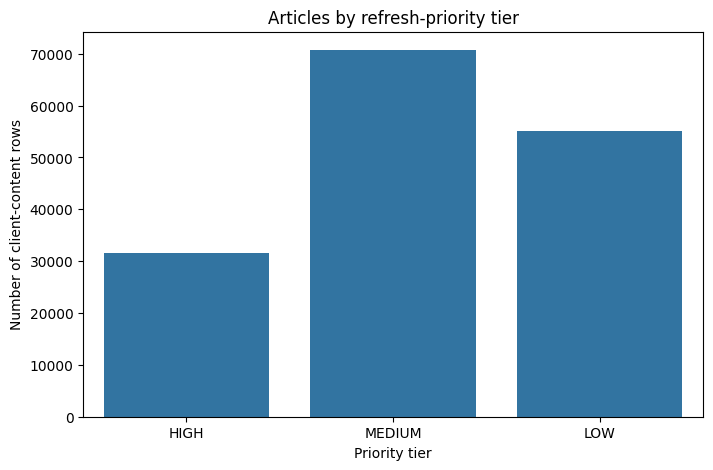

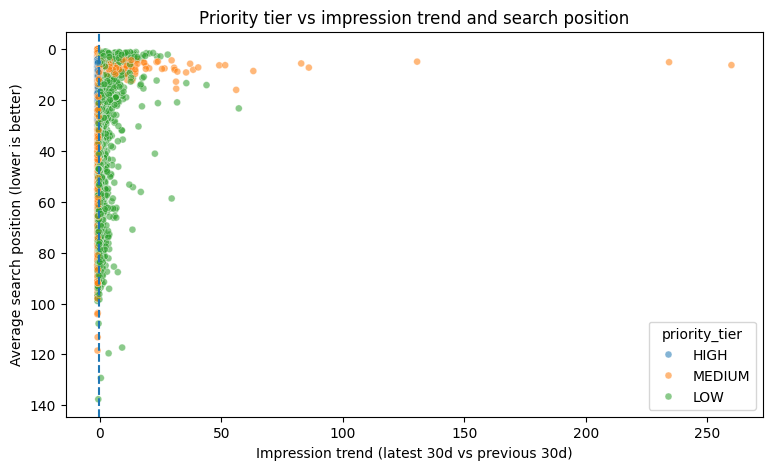

In [14]:
plt.figure(figsize=(8,5))
sns.countplot(data=recs, x="priority_tier", order=["HIGH","MEDIUM","LOW"])
plt.title("Articles by refresh-priority tier")
plt.xlabel("Priority tier")
plt.ylabel("Number of client-content rows")
plt.show()

plt.figure(figsize=(9,5))
sns.scatterplot(data=recs.sample(min(len(recs), 20000), random_state=42),
                x="trend_pct", y="pos_last30", hue="priority_tier",
                alpha=.55, s=25)
plt.axvline(-0.20, linestyle="--")
plt.gca().invert_yaxis()
plt.title("Priority tier vs impression trend and search position")
plt.xlabel("Impression trend (latest 30d vs previous 30d)")
plt.ylabel("Average search position (lower is better)")
plt.show()

## 9. Export recommendations

The CSV is designed for editorial review and includes both machine-readable metrics and human-readable explanations.

In [15]:
OUT_ALL = "flyrank_content_refresh_recommendations.csv"
OUT_HIGH = "flyrank_content_refresh_high_priority.csv"
OUT_REASON_SUMMARY = "flyrank_refresh_reason_summary.csv"

export_cols = [c for c in [
    "client_hash_id","client_label","content_hash_id","content_title","content_url","metadata_matched",
    "priority_rank","priority_score","priority_tier","refresh_recommendation",
    "reasons_text","actions_text","trend_pct","imp_last30","imp_prev30",
    "clk_last30","clk_prev30","ctr_last30","ctr_prev30","pos_last30",
    "pos_prev30","position_change","pos_volatility_60d","visible_queries",
    "rare_share","anon_share","top_query_share","content_age_days"
] if c in recs.columns]

recs.sort_values(["priority_tier","priority_score"], ascending=[True,False])[export_cols].to_csv(OUT_ALL,index=False)
recs.loc[recs["priority_tier"].eq("HIGH")].sort_values("priority_score",ascending=False)[export_cols].to_csv(OUT_HIGH,index=False)

reason_summary = (
    recs[["reasons"]].explode("reasons")
        .groupby("reasons", dropna=False).size()
        .sort_values(ascending=False).rename("article_count").to_frame()
)
reason_summary.to_csv(OUT_REASON_SUMMARY)
print("Saved:", OUT_ALL, OUT_HIGH, OUT_REASON_SUMMARY)

try:
    from google.colab import files as colab_files
    for filename in [OUT_ALL, OUT_HIGH, OUT_REASON_SUMMARY]:
        colab_files.download(filename)
except Exception as exc:
    print("Automatic browser downloads unavailable in this environment:", exc)

Saved: flyrank_content_refresh_recommendations.csv flyrank_content_refresh_high_priority.csv flyrank_refresh_reason_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. How to turn this into a production recommender

1. Have editors review recommendations and record whether each article was refreshed, why, and the date.
2. Track post-refresh outcomes against a comparable baseline (impressions, clicks, conversions, and revenue where available).
3. Add editorial review labels and post-refresh uplift as future training targets.
4. Replace heuristic weights with validated learned ranking once outcomes exist.
5. Add safeguards for seasonality, indexing problems, technical SEO, cannibalization, and low-data pages.
6. Treat age as unknown if the warehouse does not contain a reliable publication/update date.

**Current limitations:** The priority score is rule-based; “search demand” is approximated by observed impressions and visible queries; “old content” is only used if a reliable date column exists. The notebook does not claim causal lift or guaranteed traffic recovery.